# Climate Comfort Index (CCI) — 05 Evaluation & Model Export

**Student Name:** Aryan Goel | **Student ID:** 26040826

---

## 1. Final Model Diagnostics on Unseen 2025 Test Set
We inspect the selected best model (**XGBoost Regressor** / Random Forest) on the 2025 unseen holdout test set to evaluate:
1. Actual vs Predicted time-series tracking.
2. Residual error normality and homoscedasticity.
3. Feature importances across the 3 horizons.
4. Model artefact verification for FastAPI deployment.


In [1]:
import sys
import json
from pathlib import Path
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.config import CCI_MODELS_DIR
from src.model_experiments import prepare_datasets

model = joblib.load(CCI_MODELS_DIR / "model.joblib")
with open(CCI_MODELS_DIR / "metadata.json") as f:
    meta = json.load(f)

print(f"Loaded Deployed Model: {meta['algorithm']}")
print(f"Forecast Horizon: {meta['forecast_horizon']}")
print("Test Metrics:", meta['performance_metrics'])


Loaded Deployed Model: XGBoost Regressor
Forecast Horizon: Next 3 Days (+1, +2, +3 days)
Test Metrics: {'mean_rmse': 9.824, 'mean_mae': 7.478, 'mean_r2': 0.2945, 'h1_rmse': 8.9319, 'h2_rmse': 10.1634, 'h3_rmse': 10.3768}


## 2. Actual vs Predicted Time-Series Tracking (2025 Test Year)

2026-09-07 16:58:52,460 - INFO - Temporal Split -> Train: 2191 rows (2018-01-01 to 2023-12-31) | Val: 366 rows (2024-01-01 to 2024-12-31) | Test: 365 rows (2025-01-01 to 2025-12-31)


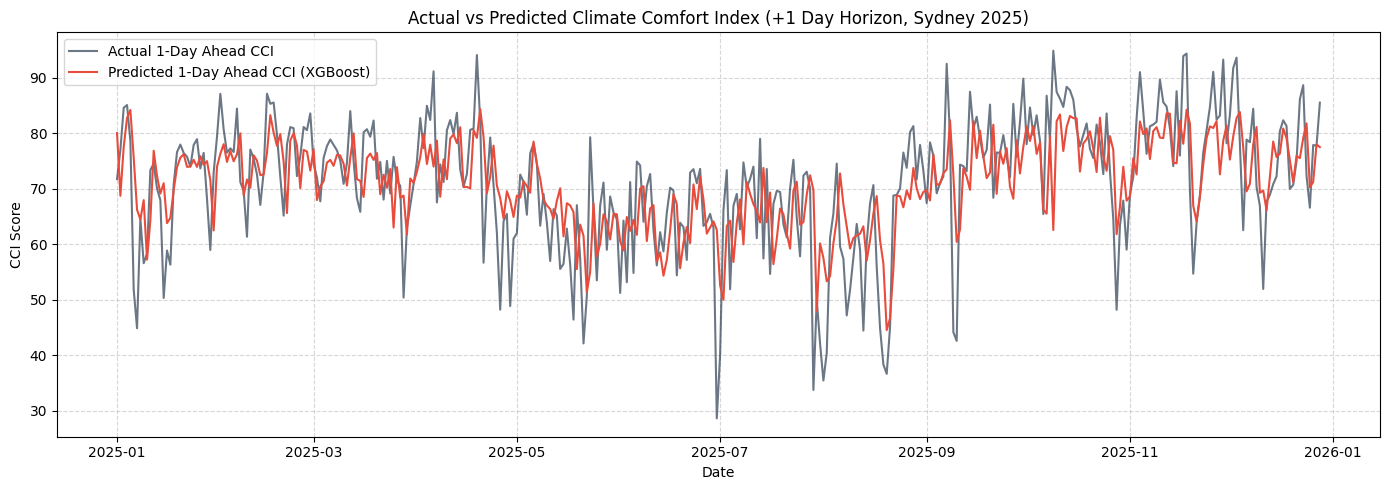

In [2]:
df, train_df, val_df, test_df, feature_cols = prepare_datasets()
ts = test_df.dropna(subset=["target_cci_h1", "target_cci_h2", "target_cci_h3"]).copy()
X_test = ts[feature_cols].fillna(train_df[feature_cols].median())
y_test = ts[["target_cci_h1", "target_cci_h2", "target_cci_h3"]]

preds = model.predict(X_test)

plt.figure(figsize=(14, 5))
plt.plot(ts["date"], y_test["target_cci_h1"], label="Actual 1-Day Ahead CCI", color="#2c3e50", alpha=0.7)
plt.plot(ts["date"], preds[:, 0], label="Predicted 1-Day Ahead CCI (XGBoost)", color="#e74c3c", linewidth=1.5)
plt.title("Actual vs Predicted Climate Comfort Index (+1 Day Horizon, Sydney 2025)")
plt.xlabel("Date")
plt.ylabel("CCI Score")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("reports/figures/cci_actual_vs_predicted_2025.png", dpi=150)
plt.show()


## 3. Residual Error Analysis

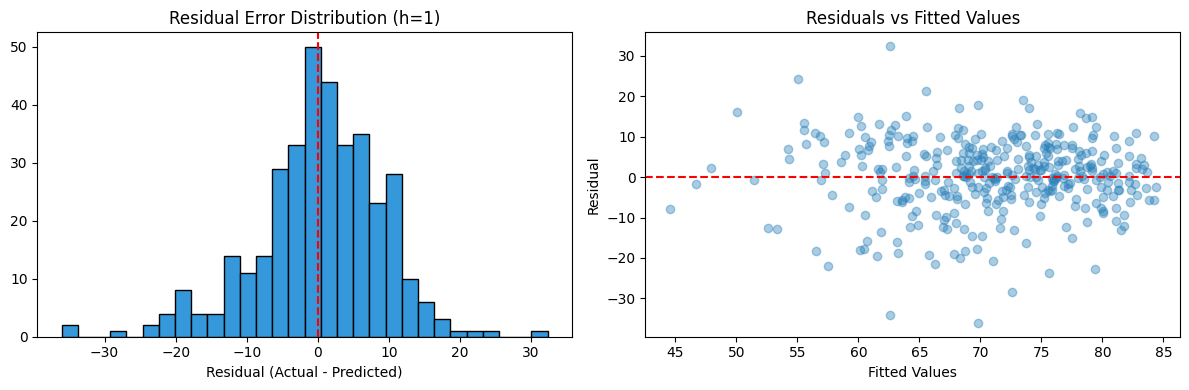

In [3]:
residuals_h1 = y_test["target_cci_h1"].values - preds[:, 0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(residuals_h1, bins=30, color="#3498db", edgecolor="black")
axes[0].set_title("Residual Error Distribution (h=1)")
axes[0].set_xlabel("Residual (Actual - Predicted)")
axes[0].axvline(0, color="red", linestyle="--")

axes[1].scatter(preds[:, 0], residuals_h1, alpha=0.4, color="#2980b9")
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residuals vs Fitted Values")
axes[1].set_xlabel("Fitted Values")
axes[1].set_ylabel("Residual")
plt.tight_layout()
plt.savefig("reports/figures/cci_residual_diagnostics.png", dpi=150)
plt.show()


## 4. Top Feature Importances

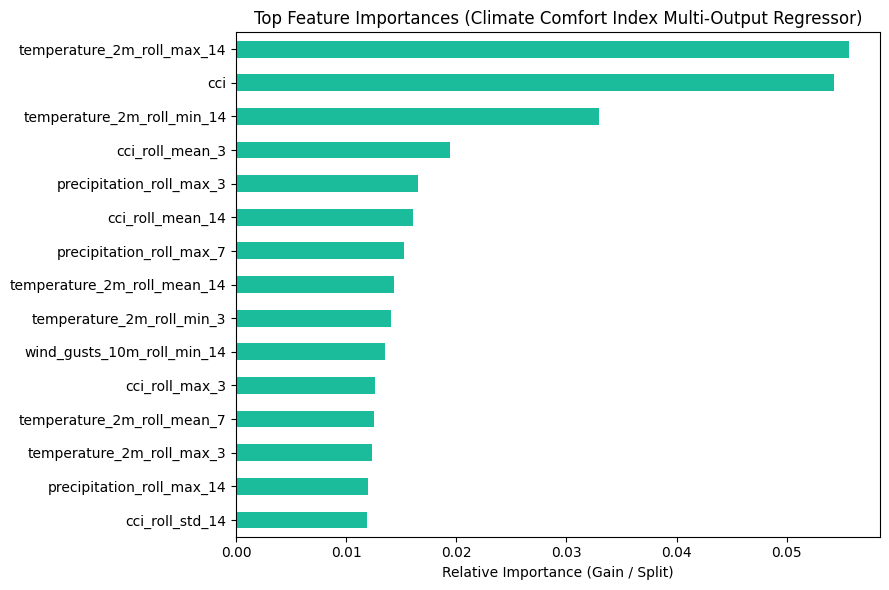

In [4]:
fi_series = pd.Series(meta["feature_importance"]).sort_values(ascending=True)

plt.figure(figsize=(9, 6))
fi_series.plot(kind="barh", color="#1abc9c")
plt.title("Top Feature Importances (Climate Comfort Index Multi-Output Regressor)")
plt.xlabel("Relative Importance (Gain / Split)")
plt.tight_layout()
plt.savefig("reports/figures/cci_feature_importance.png", dpi=150)
plt.show()


## 5. Deployment Readiness
The trained model and metadata are saved and ready for the API repository:
- `models/comfort_climate/model.joblib`
- `models/comfort_climate/metadata.json`
